# CC3+ and pH3+ cells across the decidualization stage series

* **Images:** one section per stage (uninduced, 1.5, 2.5, 3.5 and 4.5 dpi menstrual), original multichannel
  max-intensity projections (DAPI, CC3, pH3). Use the original files, not display-adjusted exports: all
  thresholds are in raw intensity units.
* **Tissue:** blurred DAPI above a fixed threshold, holes filled, largest region kept.
* **Nuclei:** Cellpose `nuclei` model on DAPI (fixed threshold + watershed if Cellpose is unavailable),
  restricted to the tissue and filtered by area.
* **CC3+ / pH3+ objects:** median despeckle, background subtraction, fixed threshold, then size and
  circularity filters. CC3 is counted within a 10 µm halo around nuclei, pH3 within nuclei.
* **Radial position:** distance of each object from the section centroid divided by the section's
  equivalent radius, `r / r_equiv` with `r_equiv = sqrt(tissue area / pi)`.

Every parameter is set once in section 3 and applied identically to all images.

**Outputs** (in `OUT_DIR`):
* `summary_counts.csv` - per image and channel: count, nuclei, % of nuclei, per mm², median `r / r_equiv`
* `parameters.json` - all parameters used
* `<image>_CC3_objects.csv`, `<image>_pH3_objects.csv` - one row per object (position, area, circularity, `r_norm`)
* `masks/` - CC3 and pH3 masks dilated by `DILATE_DISPLAY_PX` (display only), nuclei and tissue masks;
  `masks_undilated/` - true CC3 and pH3 masks; `labels/nuclei/` - nucleus label images
* `<image>_QC.png` - DAPI with tissue outline and CC3/pH3 objects
* `counts_by_stage.png`, `counts_by_stage.svg` - CC3+ and pH3+ as % of nuclei per stage
* `radial_distribution.png`, `radial_distribution.svg` - radial density of CC3+ and pH3+ objects

## 1. Libraries

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tifffile
from scipy import ndimage as ndi
from scipy.stats import gaussian_kde
from skimage import exposure, filters, measure, morphology, segmentation
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["svg.fonttype"] = "none"      # keep text editable in the SVG
plt.rcParams["pdf.fonttype"] = 42

## 2. Datasets

5 images:
  1. 1 - 20260926 - V514.1.9-MaxIP.tif
  2. 2 - 20260926 - F565.1.9-MaxIP.tif
  3. 3 - 20260926 - G890.1.6.2-MaxIP.tif
  4. 4 - 20260926 - F367.2.10-MaxIP.tif
  5. 5 - 20260926 - F351.1.1.2-MaxIP.tif

1 - 20260926 - V514.1.9-MaxIP.tif: shape (C, Y, X) = (3, 3984, 3840)


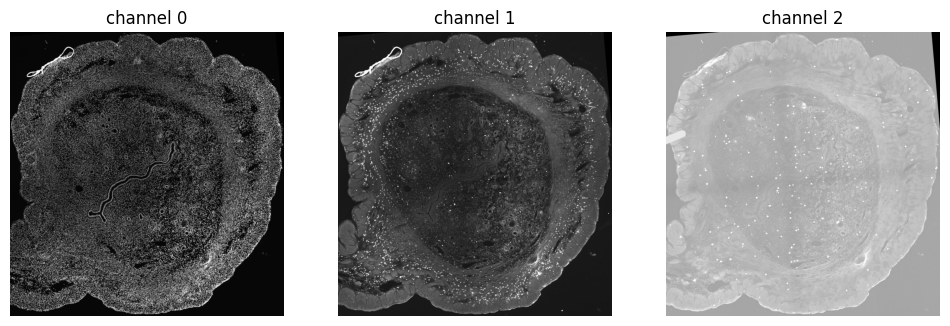

In [2]:
INPUT_DIR = Path("/n/lab_storage/mckinley_lab/Lab/Cagri/X-MensFigures/20261115_ImageSegmentation/Files")
CONTROL_FILE = None        # optional no-primary control (.tif) for calibrating THR_CC3 / THR_PH3 (section 5)


def load_channels(path):
    # Read a multichannel TIFF as a (C, Y, X) float array; the channel axis is the shortest one
    arr = np.squeeze(tifffile.imread(str(path)))
    if arr.ndim != 3:
        raise ValueError(f"{path.name}: expected 3 dims after squeeze, got {arr.shape}")
    arr = np.moveaxis(arr, int(np.argmin(arr.shape)), 0)
    return arr.astype(np.float32)


files = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in (".tif", ".tiff"))
assert files, f"No .tif files in {INPUT_DIR}"
print(f"{len(files)} images:")
for i, f in enumerate(files, 1):
    print(f"  {i}. {f.name}")

# First image, used to check channel order and calibrate thresholds
ch = load_channels(files[0])
print(f"\n{files[0].name}: shape (C, Y, X) = {ch.shape}")
fig, ax = plt.subplots(1, ch.shape[0], figsize=(4 * ch.shape[0], 4))
for i, a in enumerate(np.atleast_1d(ax)):
    a.imshow(ch[i], cmap="gray", vmax=np.percentile(ch[i], 99.5))
    a.set_title(f"channel {i}")
    a.axis("off")
plt.show()

## 3. Variables

Set once, never per image. Thresholds were chosen from the intensity histograms in section 5.

In [3]:
OUT_DIR = Path("/n/lab_storage/mckinley_lab/Lab/Cagri/X-MensFigures/20261115_ImageSegmentation/ SegmentationResults")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Image
PIXEL_SIZE = 0.6474784                 # µm per pixel (Fiji: Image > Properties)
CH_DAPI, CH_CC3, CH_PH3 = 0, 1, 2      # 0-based channel indices

# Fixed intensity thresholds (raw units)
THR_TISSUE = 60                        # blurred DAPI; in the valley of its histogram
THR_DAPI = 500                         # nuclei; used only if Cellpose is unavailable
THR_CC3 = 2000                         # after background subtraction
THR_PH3 = 450                          # after background subtraction

# CC3 / pH3 preprocessing
TOPHAT_R = 20                          # px, background scale (~2-3x object diameter): top-hat disk radius or Gaussian sigma
BG_METHOD = "tophat"                   # "tophat" (white top-hat, used for the paper) or "gaussian" (image - blur, faster)
MEDIAN_R = 2                           # px, despeckle
MEDIAN_SHAPE = "disk"                  # "disk" or "square"

# CC3 / pH3 object filters
MIN_SIZE_CC3_UM2 = 5                   # CC3 objects are fragmented, keep low
MIN_SIZE_PH3_UM2 = 5
MAX_SIZE_UM2 = 200
MIN_CIRC = 0.30                        # 4*pi*area / perimeter^2

# Nuclei
NUC_MIN_UM2 = 8
NUC_MAX_UM2 = 400                      # raise for polyploid decidual nuclei
NUC_HALO_UM = 10                       # CC3 must fall within this distance of a nucleus
USE_CELLPOSE = True                    # falls back to threshold + watershed if unavailable
CELLPOSE_GPU = True                    # set False if no CUDA device
CELLPOSE_DIAM_UM = 12

# Tissue
TISSUE_BLUR = 8                        # px, Gaussian sigma
TISSUE_MIN_UM2 = 1.0e6                 # smallest region accepted as the section

# Output
DILATE_DISPLAY_PX = 6                  # dilation of masks/CC3 and masks/pH3, DISPLAY ONLY - declare in the legend
SAVE_UNDILATED = True                  # also write the true masks to masks_undilated/
KDE_BW = 0.25                          # radial density bandwidth; larger = smoother

# Plots
STAGE_LABELS = ["uninduced", "1.5 dpi", "2.5 dpi", "3.5 dpi", "4.5 dpi"]   # one per image, in file order
BAR_COLORS = {"CC3": "#ff2d55", "pH3": "#00a0a0"}

# Everything above except paths, written to parameters.json
PARAMS = {k: globals()[k] for k in [
    "PIXEL_SIZE", "CH_DAPI", "CH_CC3", "CH_PH3", "THR_DAPI", "THR_CC3", "THR_PH3", "THR_TISSUE",
    "TOPHAT_R", "BG_METHOD", "MEDIAN_R", "MEDIAN_SHAPE", "MIN_SIZE_CC3_UM2", "MIN_SIZE_PH3_UM2",
    "MAX_SIZE_UM2", "MIN_CIRC", "NUC_MIN_UM2", "NUC_MAX_UM2", "NUC_HALO_UM", "TISSUE_BLUR",
    "TISSUE_MIN_UM2", "DILATE_DISPLAY_PX", "SAVE_UNDILATED", "KDE_BW", "USE_CELLPOSE",
    "CELLPOSE_GPU", "CELLPOSE_DIAM_UM"]}

assert BG_METHOD in ("gaussian", "tophat") and MEDIAN_SHAPE in ("disk", "square")
assert len(STAGE_LABELS) == len(files), f"{len(files)} images but {len(STAGE_LABELS)} STAGE_LABELS"
assert max(CH_DAPI, CH_CC3, CH_PH3) < ch.shape[0], f"Channel index out of range for {ch.shape[0]} channels"
print(f"Pixel size {PIXEL_SIZE} µm; thresholds: tissue {THR_TISSUE}, CC3 {THR_CC3}, pH3 {THR_PH3}")
print(f"Output: {OUT_DIR}")

Pixel size 0.6474784 µm; thresholds: tissue 60, CC3 2000, pH3 450
Output: /n/lab_storage/mckinley_lab/Lab/Cagri/20261115_ImageSegmentation/SegmentationResults


## 4. Functions

Each image goes through the same steps: tissue mask → nuclei → CC3+ and pH3+ objects → radial position.

In [4]:
def px2(um2):
    # Area in µm² -> pixels
    return um2 / PIXEL_SIZE ** 2


def tissue_mask(dapi):
    # Largest region of blurred DAPI above THR_TISSUE, holes filled
    sm = filters.gaussian(dapi, sigma=TISSUE_BLUR, preserve_range=True)
    m = ndi.binary_fill_holes(sm > THR_TISSUE)
    m = morphology.remove_small_objects(m, min_size=int(px2(TISSUE_MIN_UM2)))
    if not m.any():
        raise RuntimeError(f"Tissue mask empty: lower THR_TISSUE, or lower TISSUE_MIN_UM2 "
                           f"(currently {TISSUE_MIN_UM2 / 1e6:.3g} mm²) if the section is smaller")
    lab = measure.label(m)
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    return lab == sizes.argmax()


def section_centroid(tissue):
    # (y, x) centroid of the tissue mask; origin for the radial distances
    return measure.regionprops(tissue.astype(np.uint8))[0].centroid

In [5]:
def segment_nuclei(dapi, tissue):
    # Nucleus label image: Cellpose, or fixed threshold + distance-transform watershed as fallback
    if USE_CELLPOSE:
        try:
            from cellpose import models
            model = models.Cellpose(model_type="nuclei", gpu=CELLPOSE_GPU)
            lab, *_ = model.eval(dapi, diameter=CELLPOSE_DIAM_UM / PIXEL_SIZE, channels=[0, 0])
            lab = np.asarray(lab)
            lab[~tissue] = 0
            return lab, "cellpose"
        except Exception as e:                       # noqa: BLE001
            print(f"  cellpose unavailable ({e}); falling back to watershed")

    m = ndi.binary_fill_holes(dapi > THR_DAPI) & tissue
    m = morphology.remove_small_objects(m, min_size=int(px2(NUC_MIN_UM2)))
    dist = ndi.distance_transform_edt(m)
    peaks = morphology.h_maxima(dist, 2)
    lab = segmentation.watershed(-dist, measure.label(peaks), mask=m)
    return lab, "watershed"


def filter_nuclei(lab):
    # Keep nuclei with NUC_MIN_UM2 <= area <= NUC_MAX_UM2
    keep = np.zeros(lab.max() + 1, bool)
    for p in measure.regionprops(lab):
        if px2(NUC_MIN_UM2) <= p.area <= px2(NUC_MAX_UM2):
            keep[p.label] = True
    return keep[lab] * lab


def nucleus_halo(nuc_m):
    # Nuclei dilated by NUC_HALO_UM: the region in which CC3 is counted
    return morphology.binary_dilation(nuc_m, morphology.disk(int(round(NUC_HALO_UM / PIXEL_SIZE))))

In [6]:
def subtract_background(img):
    # Remove slowly varying background (Gaussian: image - blur, clipped at 0; or white top-hat)
    if BG_METHOD == "tophat":
        return morphology.white_tophat(img, morphology.disk(TOPHAT_R))
    bg = filters.gaussian(img, sigma=TOPHAT_R, preserve_range=True)
    return np.clip(img - bg, 0, None)


def detect_objects(sig, restrict, tissue, thr, min_size_um2):
    # Despeckle, subtract background, threshold inside `restrict` and the tissue,
    # keep objects passing the size and circularity filters. Returns (mask, one row per object)
    if MEDIAN_R > 0:
        if MEDIAN_SHAPE == "square":
            img = ndi.median_filter(sig, size=2 * MEDIAN_R + 1)
        else:
            img = ndi.median_filter(sig, footprint=morphology.disk(MEDIAN_R))
    else:
        img = sig
    img = subtract_background(img)
    lab = measure.label((img > thr) & restrict & tissue)
    rows, keep = [], np.zeros(lab.max() + 1, bool)
    for p in measure.regionprops(lab):
        if not (px2(min_size_um2) <= p.area <= px2(MAX_SIZE_UM2)):
            continue
        circ = 4 * np.pi * p.area / (p.perimeter ** 2) if p.perimeter else 0.0
        if circ < MIN_CIRC:
            continue
        keep[p.label] = True
        rows.append(dict(y=p.centroid[0], x=p.centroid[1],
                         area_um2=p.area * PIXEL_SIZE ** 2, circularity=circ))
    return keep[lab] > 0, pd.DataFrame(rows)

In [7]:
def save_tif(arr, outdir, sub, path, index):
    # Write outdir/sub/<index>_<image>.tif
    d = outdir / sub
    d.mkdir(parents=True, exist_ok=True)
    prefix = f"{index:03d}_" if index is not None else ""
    tifffile.imwrite(d / f"{prefix}{path.stem}.tif", arr)


def save_mask(mask, outdir, sub, path, index):
    save_tif((mask * 255).astype(np.uint8), outdir, sub, path, index)


def qc_overlay(dapi, cc3_m, ph3_m, tissue, out):
    # DAPI with tissue outline and CC3 / pH3 object pixels
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(exposure.rescale_intensity(dapi, in_range=(0, np.percentile(dapi, 99.5))), cmap="gray")
    ax.contour(tissue, levels=[0.5], colors="white", linewidths=0.6)
    yy, xx = np.where(cc3_m); ax.scatter(xx, yy, s=0.6, c="magenta", lw=0, label="CC3")
    yy, xx = np.where(ph3_m); ax.scatter(xx, yy, s=0.6, c="cyan", lw=0, label="pH3")
    ax.axis("off")
    ax.legend(markerscale=12, loc="lower right", framealpha=0.3)
    fig.savefig(out, dpi=180, bbox_inches="tight")
    plt.close(fig)


def process(path, outdir, index=None):
    # Segment one image and write its masks, object tables and QC overlay.
    # Returns (summary rows, objects table)
    print(f"[{path.name}]")
    outdir.mkdir(parents=True, exist_ok=True)
    ch = load_channels(path)
    dapi = ch[CH_DAPI]
    tis = tissue_mask(dapi)
    tissue_um2 = tis.sum() * PIXEL_SIZE ** 2

    nuc_lab, how = segment_nuclei(dapi, tis)
    nuc_lab = filter_nuclei(nuc_lab)
    n_nuclei = int(len(np.unique(nuc_lab)) - 1)
    nuc_m = nuc_lab > 0
    save_mask(nuc_m, outdir, "masks/nuclei", path, index)
    save_tif(nuc_lab.astype(np.uint16 if nuc_lab.max() < 65535 else np.uint32),
             outdir, "labels/nuclei", path, index)
    halo = nucleus_halo(nuc_m)
    print(f"  tissue {tissue_um2 / 1e6:.2f} mm2 | nuclei {n_nuclei} ({how})")

    cy, cx = section_centroid(tis)
    r_equiv = np.sqrt(tis.sum() / np.pi)

    rows, objects, masks = [], [], {}
    for name, chan, thr, restrict, minsz in (
        ("CC3", CH_CC3, THR_CC3, halo, MIN_SIZE_CC3_UM2),
        ("pH3", CH_PH3, THR_PH3, nuc_m, MIN_SIZE_PH3_UM2),
    ):
        m, df = detect_objects(ch[chan], restrict, tis, thr, minsz)
        masks[name] = m
        if len(df):
            df["r_norm"] = np.hypot(df.y - cy, df.x - cx) / r_equiv
        df.insert(0, "image", path.stem)
        df.insert(1, "channel", name)
        df.to_csv(outdir / f"{path.stem}_{name}_objects.csv", index=False)
        objects.append(df)

        save_mask(morphology.binary_dilation(m, morphology.disk(DILATE_DISPLAY_PX)),
                  outdir, f"masks/{name}", path, index)
        if SAVE_UNDILATED:
            save_mask(m, outdir, f"masks_undilated/{name}", path, index)

        n = len(df)
        rows.append(dict(image=path.stem, channel=name, count=n, nuclei=n_nuclei,
                         percent_of_nuclei=100.0 * n / n_nuclei if n_nuclei else np.nan,
                         tissue_mm2=tissue_um2 / 1e6,
                         per_mm2=n / (tissue_um2 / 1e6),
                         median_r_norm=float(df.r_norm.median()) if n else np.nan,
                         nucleus_method=how))
        print(f"  {name}: {n} objects, {rows[-1]['percent_of_nuclei']:.2f}% of nuclei")

    save_mask(tis, outdir, "masks/tissue", path, index)
    qc_overlay(dapi, masks["CC3"], masks["pH3"], tis, outdir / f"{path.stem}_QC.png")
    return rows, pd.concat(objects, ignore_index=True)

## 5. Calibrate thresholds on the first image

Diagnostics only; nothing here is written to `OUT_DIR` except the optional no-primary control.
`THR_CC3` and `THR_PH3` should return ~0 objects on the no-primary control.

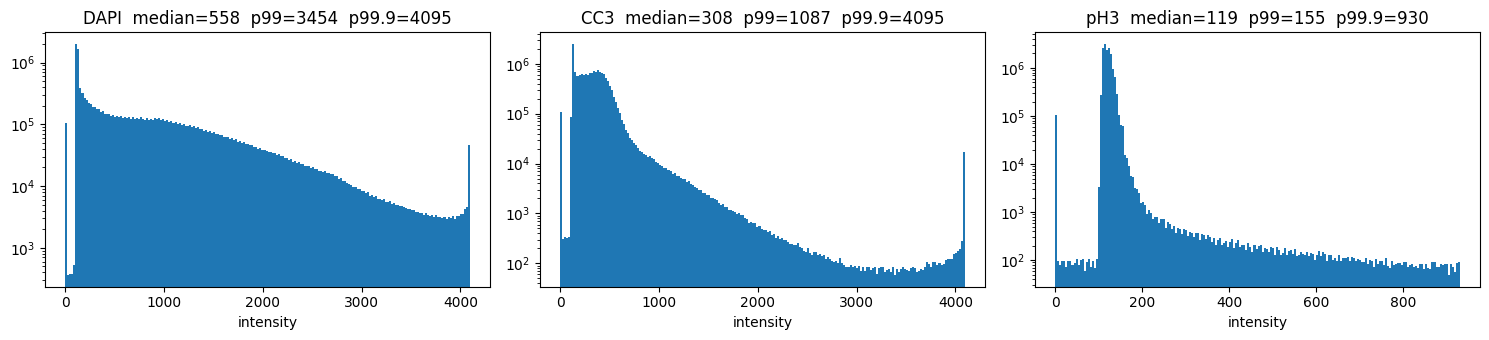

DAPI max: 4095.0 p99=3454 p99.5=3898 p99.9=4095 p99.95=4095 p99.99=4095 p99.999=4095
CC3 max: 4095.0 p99=1087 p99.5=1397 p99.9=4095 p99.95=4095 p99.99=4095 p99.999=4095
pH3 max: 4095.0 p99=155 p99.5=170 p99.9=930 p99.95=1733 p99.99=3565 p99.999=4095


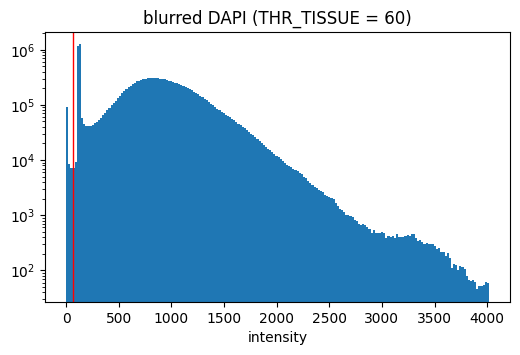

blurred DAPI percentiles: p1=111 p5=116 p10=123 p25=508 p50=820 p75=1098


In [8]:
# Raw intensity distributions per channel
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (name, idx) in zip(ax, [("DAPI", CH_DAPI), ("CC3", CH_CC3), ("pH3", CH_PH3)]):
    v = ch[idx].ravel()
    a.hist(v, bins=200, range=(0, np.percentile(v, 99.9)), log=True)
    a.set_title(f"{name}  median={np.median(v):.0f}  p99={np.percentile(v, 99):.0f}  "
                f"p99.9={np.percentile(v, 99.9):.0f}")
    a.set_xlabel("intensity")
plt.tight_layout()
plt.show()

for name, idx in [("DAPI", CH_DAPI), ("CC3", CH_CC3), ("pH3", CH_PH3)]:
    v = ch[idx].ravel()
    print(name, "max:", v.max(), " ".join(f"p{q}={np.percentile(v, q):.0f}"
                                          for q in [99, 99.5, 99.9, 99.95, 99.99, 99.999]))

# Blurred DAPI: THR_TISSUE goes in the valley
sm = filters.gaussian(ch[CH_DAPI], sigma=TISSUE_BLUR, preserve_range=True)
fig, a = plt.subplots(figsize=(6, 3.5))
a.hist(sm.ravel(), bins=200, log=True)
a.axvline(THR_TISSUE, color="r", lw=1)
a.set_title(f"blurred DAPI (THR_TISSUE = {THR_TISSUE})")
a.set_xlabel("intensity")
plt.show()
print("blurred DAPI percentiles:", " ".join(f"p{q}={np.percentile(sm, q):.0f}" for q in [1, 5, 10, 25, 50, 75]))

tissue 6.37 mm2, 99.3% of frame
nuclei 22302 (cellpose)   CC3 74   pH3 120


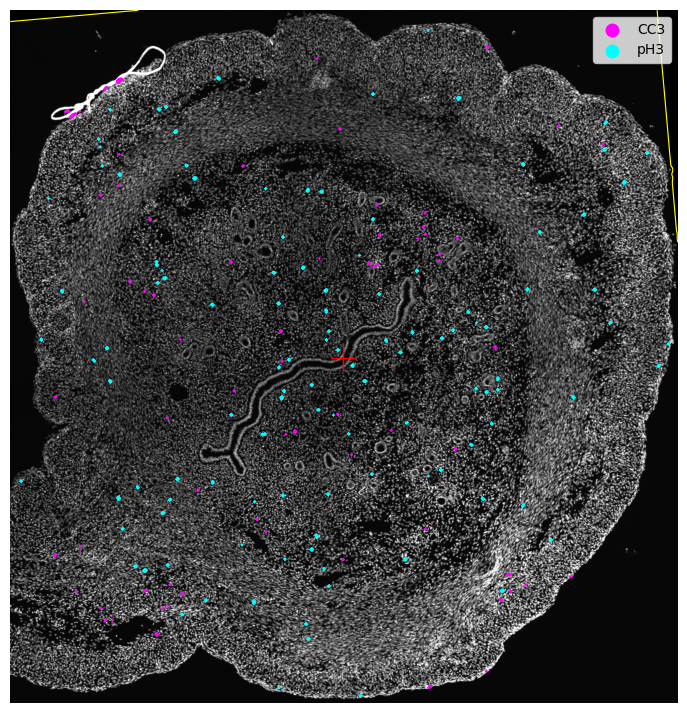

In [9]:
# Tissue mask, section centroid, nuclei and CC3 / pH3 objects, exactly as in section 6
tis = tissue_mask(ch[CH_DAPI])
cy, cx = section_centroid(tis)
print(f"tissue {tis.sum() * PIXEL_SIZE ** 2 / 1e6:.2f} mm2, {100 * tis.mean():.1f}% of frame")

lab, how = segment_nuclei(ch[CH_DAPI], tis)
lab = filter_nuclei(lab)
nuc = lab > 0
cc3_m, cc3_df = detect_objects(ch[CH_CC3], nucleus_halo(nuc), tis, THR_CC3, MIN_SIZE_CC3_UM2)
ph3_m, ph3_df = detect_objects(ch[CH_PH3], nuc, tis, THR_PH3, MIN_SIZE_PH3_UM2)
print(f"nuclei {len(np.unique(lab)) - 1} ({how})   CC3 {len(cc3_df)}   pH3 {len(ph3_df)}")

fig, a = plt.subplots(figsize=(9, 9))
a.imshow(ch[CH_DAPI], cmap="gray", vmax=np.percentile(ch[CH_DAPI], 99.5))
a.contour(tis, [0.5], colors="yellow", linewidths=0.8)
yy, xx = np.where(cc3_m); a.scatter(xx, yy, s=1, c="magenta", lw=0, label="CC3")
yy, xx = np.where(ph3_m); a.scatter(xx, yy, s=1, c="cyan", lw=0, label="pH3")
a.plot(cx, cy, "r+", ms=18)
a.axis("off")
a.legend(markerscale=10)
plt.show()

In [10]:
# Optional: no-primary control (set CONTROL_FILE in section 2); written to OUT_DIR/no_primary_control
if CONTROL_FILE is not None:
    ctrl_rows, _ = process(Path(CONTROL_FILE), OUT_DIR / "no_primary_control", 1)
    display(pd.DataFrame(ctrl_rows))
else:
    print("No CONTROL_FILE set; skipped")

No CONTROL_FILE set; skipped


## 6. Segment and quantify all images

In [11]:
rows, objects = [], []
for i, f in enumerate(files, 1):
    r, o = process(f, OUT_DIR, i)
    rows += r
    objects.append(o)
summary = pd.DataFrame(rows)
objects = pd.concat(objects, ignore_index=True)
summary

[1 - 20260926 - V514.1.9-MaxIP.tif]
  tissue 6.37 mm2 | nuclei 22302 (cellpose)
  CC3: 74 objects, 0.33% of nuclei
  pH3: 120 objects, 0.54% of nuclei
[2 - 20260926 - F565.1.9-MaxIP.tif]


more than 65535 masks in image, masks returned as np.uint32


  tissue 24.70 mm2 | nuclei 70062 (cellpose)
  CC3: 88 objects, 0.13% of nuclei
  pH3: 798 objects, 1.14% of nuclei
[3 - 20260926 - G890.1.6.2-MaxIP.tif]


more than 65535 masks in image, masks returned as np.uint32


  tissue 25.29 mm2 | nuclei 86652 (cellpose)
  CC3: 71 objects, 0.08% of nuclei
  pH3: 1300 objects, 1.50% of nuclei
[4 - 20260926 - F367.2.10-MaxIP.tif]


more than 65535 masks in image, masks returned as np.uint32


  tissue 34.53 mm2 | nuclei 126163 (cellpose)
  CC3: 348 objects, 0.28% of nuclei
  pH3: 2182 objects, 1.73% of nuclei
[5 - 20260926 - F351.1.1.2-MaxIP.tif]


more than 65535 masks in image, masks returned as np.uint32


  tissue 75.29 mm2 | nuclei 129120 (cellpose)
  CC3: 1420 objects, 1.10% of nuclei
  pH3: 162 objects, 0.13% of nuclei


,image,channel,count,nuclei,percent_of_nuclei,tissue_mm2,per_mm2,median_r_norm,nucleus_method
0,1 - 20260926 - V514.1.9-MaxIP,CC3,74,22302,0.331809,6.369044,11.618698,0.596972,cellpose
1,1 - 20260926 - V514.1.9-MaxIP,pH3,120,22302,0.538068,6.369044,18.841133,0.530570,cellpose
2,2 - 20260926 - F565.1.9-MaxIP,CC3,88,70062,0.125603,24.700291,3.562711,0.459204,cellpose
3,2 - 20260926 - F565.1.9-MaxIP,pH3,798,70062,1.138991,24.700291,32.307312,0.480654,cellpose
4,3 - 20260926 - G890.1.6.2-MaxIP,CC3,71,86652,0.081937,25.289624,2.807476,0.453311,cellpose
5,3 - 20260926 - G890.1.6.2-MaxIP,pH3,1300,86652,1.500254,25.289624,51.404482,0.472615,cellpose
6,4 - 20260926 - F367.2.10-MaxIP,CC3,348,126163,0.275834,34.527017,10.079064,0.357447,cellpose
7,4 - 20260926 - F367.2.10-MaxIP,pH3,2182,126163,1.729509,34.527017,63.196888,0.651139,cellpose
8,5 - 20260926 - F351.1.1.2-MaxIP,CC3,1420,129120,1.099752,75.293595,18.859506,0.331294,cellpose
9,5 - 20260926 - F351.1.1.2-MaxIP,pH3,162,129120,0.125465,75.293595,2.151577,0.794526,cellpose


## 7. Plot: CC3+ and pH3+ as % of nuclei

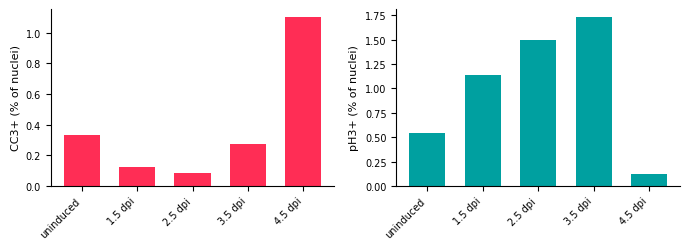

In [12]:
order = [f.stem for f in files]
fig, ax = plt.subplots(1, 2, figsize=(7, 2.6))
for a, name in zip(ax, ["CC3", "pH3"]):
    d = summary[summary.channel == name].set_index("image").loc[order]
    a.bar(range(len(d)), d.percent_of_nuclei, width=0.65, color=BAR_COLORS[name])
    a.set_xticks(range(len(d)))
    a.set_xticklabels(STAGE_LABELS, rotation=45, ha="right", fontsize=7)
    a.tick_params(axis="y", labelsize=7)
    a.set_ylabel(f"{name}+ (% of nuclei)", fontsize=8)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "counts_by_stage.png", dpi=300)
plt.savefig(OUT_DIR / "counts_by_stage.svg")
plt.show()

## 8. Plot: radial distribution of CC3+ and pH3+ objects

Gaussian kernel density of `r / r_equiv` per image (bandwidth `KDE_BW`); curves need at least 3 objects.

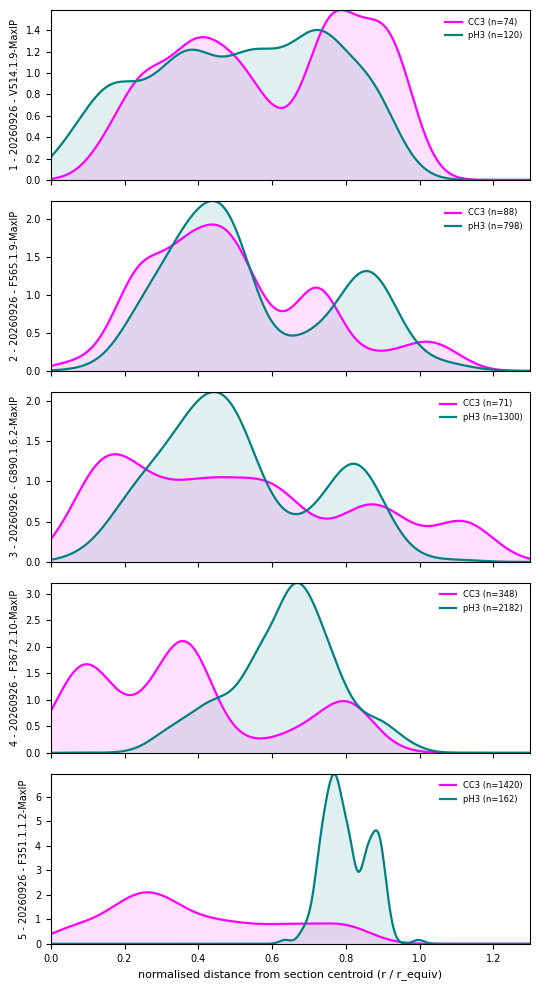

In [13]:
grid = np.linspace(0, 1.3, 400)
imgs = sorted(objects.image.unique())
fig, axes = plt.subplots(len(imgs), 1, figsize=(5.5, 2.0 * len(imgs)), sharex=True, squeeze=False)
for ax, im in zip(axes[:, 0], imgs):
    for name, col in (("CC3", "magenta"), ("pH3", "teal")):
        v = objects[(objects.image == im) & (objects.channel == name)].r_norm.dropna().values
        if len(v) < 3 or np.ptp(v) == 0:
            continue
        try:
            y = gaussian_kde(v, bw_method=KDE_BW)(grid)
        except np.linalg.LinAlgError:
            continue
        ax.plot(grid, y, color=col, lw=1.6, label=f"{name} (n={len(v)})")
        ax.fill_between(grid, y, color=col, alpha=0.12, lw=0)
    ax.set_ylabel(im, fontsize=7)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=6, frameon=False)
    ax.set_xlim(0, 1.3)
    ax.margins(y=0)
axes[-1, 0].set_xlabel("normalised distance from section centroid (r / r_equiv)", fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "radial_distribution.png", dpi=200)
fig.savefig(OUT_DIR / "radial_distribution.svg")
plt.show()

## 9. Save summary table and parameters

In [14]:
summary.to_csv(OUT_DIR / "summary_counts.csv", index=False)
(OUT_DIR / "parameters.json").write_text(json.dumps(PARAMS, indent=2))
print(f"Saved summary_counts.csv ({len(summary)} rows) and parameters.json to {OUT_DIR}")

Saved summary_counts.csv (10 rows) and parameters.json to /n/lab_storage/mckinley_lab/Lab/Cagri/20261115_ImageSegmentation/SegmentationResults
